# 08. Symulacja harmonogramów prób reakcji (COG-BCI, zadanie PVT)

Zadanie B8 (strumień „B. Dane i dowody”, SHOULD), issue #23. Cel: ustawić odstępy prób reakcji z issue #14 i #15
(`probe_*` w `src/wachta/config.py`, drabina 20 → 10 → 5 min z `docs/analiza-i-adaptacja.md` §5).

Notebook 06 pokazał, że podprogowa alfa potyliczna przy otwartych oczach **nie przewiduje** lapsu w następnej minucie
(AUC na osobę 0,52). Pytanie nie brzmi więc „czy alfa przewiduje”, tylko: **który harmonogram prób reakcji łapie najwięcej
lapsów na jedną próbę** i czy wyzwalanie przez EEG dodaje coś ponad zwykły harmonogram.

**Dane:** te same nagrania co w notebooku 06: COG-BCI (Hinss i in., Zenodo 7413650), PVT ok. 10 min, 90 bodźców co 2–10 s,
29 osób × 3 sesje, oczy otwarte, osoby wypoczęte. Czasy reakcji ze znaczników EEG (13 = bodziec, 14 = reakcja),
bo pliki `behavioral/PVT.mat` nie pasują do nagrań (notebook 06, sekcja 1). EEG przetworzone jak w produkcie
(8 kanałów, referencja Fp1, okna 2 s co 1 s, kalibracja z pierwszych 60 czystych okien, wskaźnik szybki = mediana z 5 okien).

**Jak symulujemy próbę.** Próba reakcji produktu to jedna reakcja na bodziec (`VigilanceIndex.record_probe`). W PVT bodźce
pojawiają się co ok. 7 s, więc za „własną odpowiedź” próby wstawionej w chwili *t* bierzemy pierwszą próbę PVT, która zaczyna się
w ciągu 15 s po *t*. Harmonogram działa tylko po kalibracji (wskaźnik EEG wcześniej nie istnieje). Trzy sesje jednej osoby
sklejamy w jedną oś czasu (ok. 27 min na osobę), żeby dłuższe odstępy i drabina adaptacyjna miały na czym działać.
Sesje dzieli tydzień, więc to uproszczenie.

**Zasady:** jednostką niepewności jest **osoba** (bootstrap po osobach, 2000 losowań; nigdy nie traktujemy okien ani prób
jako niezależnych). Harmonogramy z losową fazą (stałe, adaptacyjne) uśredniamy po 200 losowych fazach. Każdy harmonogram
porównujemy z **losowym harmonogramem o tej samej liczbie prób u tej samej osoby** (próby w losowych chwilach).

In [1]:
%pip install -q mne remotezip

In [2]:
import shutil
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from remotezip import RemoteZip
from scipy.signal import welch

mne.set_log_level("ERROR")
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 85, "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.width", 200)

OUR_CH = ["F3", "F4", "C3", "C4", "P3", "P4", "O1", "O2"]
FS = 250
WIN_S, STEP_S = 2.0, 1.0
REJECT_UV = 300          # config.reject_uv
CAL_WINDOWS = 60         # config.cal_windows
SMOOTH = 5               # config.smooth_windows (causal median = product "fast index")
EPS = 1e-12
LAPSE_MS = 500           # classic PVT lapse
LAPSE_B_MS = 355         # PVT-B lapse threshold, config.probe_lapse_ms

# Product detector and probe parameters, copied from src/wachta/config.py (read-only here)
Z_ENTER, Z_EXIT, LAPSE_MIN_S, LAPSE_EXIT_S = 2.5, 1.0, 3.0, 2.0
PROBE_Z, PROBE_MIN_S, PROBE_COOLDOWN_S = 1.5, 2.0, 45.0
QUALITY_WINDOW_S, QUALITY_MIN = 30.0, 0.5

SUBJECTS = [f"sub-{i:02d}" for i in range(1, 30)]
SESSIONS = ["S1", "S2", "S3"]

# Same cache as notebooks 05/06: small per-recording tables outside the repo.
DATA = Path("/content/data") if Path("/content").exists() else Path.home() / ".cache" / "wachta-eeg"
RAW_DIR = DATA / "cogbci-pvt-b5"
RES_DIR = DATA / "cogbci-pvt-b5-results"
RES_DIR.mkdir(parents=True, exist_ok=True)
COG_URL = "https://zenodo.org/records/7413650/files/{sub}.zip?download=1"
RNG = np.random.default_rng(8)

## 1. Dane: cache albo pobranie

Ten sam kod i ten sam katalog cache co w notebookach 05 i 06 (małe tabele: cechy okien 2 s i znaczniki PVT na nagranie).
Jeśli tabele istnieją, nic nie pobieramy. Na świeżym Colabie komórka pobiera z Zenodo tylko pliki `PVT.set`/`PVT.fdt`
(ok. 77 MB na sesję, razem ok. 6,7 GB przez zapytania z zakresem; trwa to ok. 40–45 min) i od razu kasuje surowe pliki.

In [3]:
PVT_CODES = {"11", "12", "13", "14", "15"}   # trial/ISI start, ISI error (false start), stimulus, response, end


def eeg_window_table(raw):
    """Hardware-like pipeline: 8 channels, Fp1 reference, 1-40 Hz, 250 Hz, 2 s windows / 1 s step.

    Features follow src/wachta/features.py (alpha_prom, alpha_occ). `t_end` is the end of the window,
    i.e. the moment the product would know the value.
    """
    r = raw.copy()
    r.set_eeg_reference(["Fp1"], projection=False)       # BrainAccess MINI: hardware reference at Fp1
    r.pick(OUR_CH).reorder_channels(OUR_CH)
    r.filter(1.0, 40.0, fir_design="firwin", verbose=False).resample(FS)
    ep = mne.make_fixed_length_epochs(r, duration=WIN_S, overlap=WIN_S - STEP_S, preload=True)
    x = ep.get_data() * 1e6                              # µV
    ptp = np.ptp(x, axis=-1).max(1)
    f, p = welch(x, FS, nperseg=int(WIN_S * FS), axis=-1)
    dfh = f[1] - f[0]
    occ = p[:, 6:8].mean(1)                              # mean PSD over O1/O2
    bmean = lambda lo, hi: occ[:, (f >= lo) & (f <= hi)].mean(1)
    alpha_pow = p[:, 6:8][:, :, (f >= 8) & (f <= 12)].sum(-1) * dfh
    t_start = ep.events[:, 0] / FS
    return pd.DataFrame({
        "t_end": t_start + WIN_S,
        "alpha_prom": np.log10((bmean(8, 12) + EPS) / (np.sqrt(bmean(5, 7) * bmean(14, 16)) + EPS)),
        "alpha_occ": np.log10(alpha_pow.mean(1) + EPS),
        "ptp_uv": ptp,
    })


def fetch_and_process(sub, retries=4):
    """Range-request only PVT.set/.fdt of one subject, compute small tables, delete raw files."""
    done = lambda ses: (RES_DIR / f"{sub}_{ses}_win.csv").exists()
    if all(done(s) for s in SESSIONS):
        return "cache"
    for attempt in range(retries):
        try:
            with RemoteZip(COG_URL.format(sub=sub)) as z:
                names = [n for n in z.namelist() if n.endswith(("/eeg/PVT.set", "/eeg/PVT.fdt"))]
                for n in names:
                    ses = n.split("/ses-")[1][:2]
                    if ses in SESSIONS and not done(ses):
                        z.extract(n, RAW_DIR / sub)
            break
        except Exception as e:                           # network hiccups on Zenodo
            print(f"  {sub}: attempt {attempt + 1} failed ({e})")
            time.sleep(30 * (attempt + 1))
    for path in sorted((RAW_DIR / sub).rglob("ses-*/eeg/PVT.set")):
        ses = path.parent.parent.name[4:]
        try:
            raw = mne.io.read_raw_eeglab(path, preload=True)
            ann = pd.DataFrame({"onset": raw.annotations.onset, "code": raw.annotations.description})
            ann[ann.code.isin(PVT_CODES)].to_csv(RES_DIR / f"{sub}_{ses}_events.csv", index=False)
            eeg_window_table(raw).round(5).to_csv(RES_DIR / f"{sub}_{ses}_win.csv", index=False)
        except Exception as e:
            print(f"  {sub} {ses}: processing error ({e})")
    shutil.rmtree(RAW_DIR / sub, ignore_errors=True)
    return "downloaded"

In [4]:
t_start = time.time()
for sub in SUBJECTS:
    status = fetch_and_process(sub)
    if status != "cache":
        print(f"{sub}: pobrane ({time.time() - t_start:.0f} s od startu)")
print(f"tabel w cache: {len(list(RES_DIR.glob('*_win.csv')))} nagrań")

tabel w cache: 87 nagrań


## 2. Nagrania i częstość lapsów

Przygotowanie nagrania jest identyczne jak w notebooku 06 (`prepare_recording`): okres zadania, odrzucenie okien > 300 µV,
kalibracja osobista, z-score i wskaźnik szybki.

In [5]:
def trials_from_events(ev):
    """Stimulus (13) followed by a response (14) before the next stimulus -> one trial with RT in ms.
    A response logged at the same instant as the stimulus (RT < 100 ms) is an anticipation / key already
    pressed: it is counted as a false start and its RT is set to NaN (neither a lapse nor a valid reaction)."""
    on, code = ev.onset.values, ev.code.astype(str).values
    stim, resp = on[code == "13"], on[code == "14"]
    rows = []
    for i, s in enumerate(stim):
        nxt_stim = stim[i + 1] if i + 1 < len(stim) else np.inf
        r = resp[(resp >= s) & (resp < nxt_stim)]
        rows.append((s, (r[0] - s) * 1000 if len(r) else np.nan))
    tr = pd.DataFrame(rows, columns=["t", "rt_ms"])
    tr["anticip"] = tr.rt_ms < 100
    tr.loc[tr.anticip, "rt_ms"] = np.nan
    tr["t_resp"] = tr.t + tr.rt_ms / 1000
    return tr


def false_starts(ev):
    """Two candidate markers: ISI-error trigger (12), and responses with no stimulus since the last trial start (11)."""
    code, on = ev.code.astype(str).values, ev.onset.values
    n12 = int((code == "12").sum())
    orphan, armed = 0, False
    for c in code:
        if c == "11":
            armed = False
        elif c == "13":
            armed = True
        elif c == "14":
            if not armed:
                orphan += 1
            armed = False
    return n12, orphan


def robust_baseline(x):
    """Median and scaled MAD with the same fallbacks as src/wachta/baseline.py."""
    c = np.median(x)
    s = np.median(np.abs(x - c)) * 1.4826
    if s <= 1e-6:
        s = x.std() if x.std() > 1e-6 else 1.0
    return c, s


def causal_median(z, n=SMOOTH):
    """Product fast index: median of the last n windows, NaN-aware, needs (n+1)//2 valid values."""
    out = np.full(len(z), np.nan)
    for i in range(len(z)):
        v = z[max(0, i - n + 1): i + 1]
        v = v[~np.isnan(v)]
        if len(v) >= (n + 1) // 2:
            out[i] = np.median(v)
    return out


def prepare_recording(sub, ses):
    ev = pd.read_csv(RES_DIR / f"{sub}_{ses}_events.csv", dtype={"code": str})
    W = pd.read_csv(RES_DIR / f"{sub}_{ses}_win.csv")
    code = ev.code.values
    t0 = ev.onset[code == "11"].min()
    t1 = ev.onset[code == "15"].max() if (code == "15").any() else ev.onset.max()
    tr = trials_from_events(ev)
    W = W[(W.t_end - WIN_S >= t0) & (W.t_end <= t1)].reset_index(drop=True)   # task period only
    W["bad"] = W.ptp_uv > REJECT_UV
    clean = W.index[~W.bad]
    cal = clean[:CAL_WINDOWS]
    cal_end = W.t_end[cal[-1]]
    for col in ["alpha_prom", "alpha_occ"]:
        c, s = robust_baseline(W.loc[cal, col].values)
        z = (W[col] - c) / s
        z[W.bad] = np.nan
        z[W.t_end <= cal_end] = np.nan            # the product has no z-score until calibration is done
        W[col + "_z"] = z
    W["fast"] = causal_median(W.alpha_prom_z.values)
    fs12, orphan = false_starts(ev)
    info = dict(subject=sub, session=ses, t0=t0, t1=t1, cal_end=cal_end, dur_min=(t1 - t0) / 60,
                cal_min=(cal_end - t0) / 60, n_trials=len(tr), n_anticip=int(tr.anticip.sum()), n_no_resp=int((tr.rt_ms.isna() & ~tr.anticip).sum()),
                rt_median=tr.rt_ms.median(), lapses500=int((tr.rt_ms > LAPSE_MS).sum()),
                lapses355=int((tr.rt_ms > LAPSE_B_MS).sum()), isi_error_12=fs12, orphan_resp=orphan,
                eeg_rej_pct=100 * W.bad.mean())
    return W, tr, info


RECS, WINS, TRIALS = [], {}, {}
for sub in SUBJECTS:
    for ses in SESSIONS:
        if (RES_DIR / f"{sub}_{ses}_win.csv").exists():
            W, tr, info = prepare_recording(sub, ses)
            RECS.append(info)
            WINS[sub, ses], TRIALS[sub, ses] = W, tr
RECS = pd.DataFrame(RECS)
print(f"{RECS.subject.nunique()} osób, {len(RECS)} nagrań PVT")

29 osób, 87 nagrań PVT


In [6]:
hours = sum((r.t1 - r.cal_end) / 3600 for r in RECS.itertuples())
post = pd.concat([t[t.t >= RECS[(RECS.subject == s) & (RECS.session == ses)].cal_end.iloc[0]].assign(subject=s)
                  for (s, ses), t in TRIALS.items()])
print(f"czas po kalibracji (tu działają wszystkie harmonogramy): {hours:.1f} h w {len(RECS)} nagraniach, "
      f"na osobę {hours / RECS.subject.nunique() * 60:.0f} min (3 sesje sklejone)")
print(f"próby PVT po kalibracji: {len(post)}; średni odstęp między bodźcami "
      f"{np.nanmean(np.diff(TRIALS['sub-01', 'S1'].t)):.1f} s; brak reakcji: {RECS.n_no_resp.sum()}")
for thr in (LAPSE_MS, LAPSE_B_MS):
    per = post.groupby("subject").rt_ms.apply(lambda r: (r > thr).mean())
    print(f"RT > {thr} ms: {(post.rt_ms > thr).sum()} prób = {100 * (post.rt_ms > thr).mean():.1f}% wszystkich; "
          f"na osobę mediana {100 * per.median():.1f}% (IQR {100 * per.quantile(.25):.1f}–{100 * per.quantile(.75):.1f}%)")

czas po kalibracji (tu działają wszystkie harmonogramy): 13.1 h w 87 nagraniach, na osobę 27 min (3 sesje sklejone)
próby PVT po kalibracji: 6839; średni odstęp między bodźcami 6.7 s; brak reakcji: 0
RT > 500 ms: 174 prób = 2.5% wszystkich; na osobę mediana 1.8% (IQR 0.8–2.9%)
RT > 355 ms: 1767 prób = 25.8% wszystkich; na osobę mediana 21.6% (IQR 16.6–37.7%)


## 3. Co znaczy „złapać” laps

Lapsy u wypoczętych osób są rzadkie i zwykle pojedyncze. Definiujemy:

- **Epizod lapsu:** wolne reakcje (RT > próg), których bodźce dzieli ≤ 30 s, łączymy w jeden epizod
  (wariant 60 s w sekcji 7). Analizujemy dwa progi: **500 ms** (klasyczny laps) i **355 ms** (próg PVT-B, `probe_lapse_ms`).
- **Okno epizodu:** od 3 s przed pierwszym wolnym bodźcem do 3 s po ostatnim (3 s to ok. połowa średniego odstępu między
  bodźcami, więc w tym oknie najbliższą reakcją próby jest wolna reakcja z epizodu).
- **Definicja główna, „złapany w trakcie”:** co najmniej jedna próba wypada w oknie epizodu. Uzasadnienie: próba ma sens tylko wtedy,
  gdy jej *własna* odpowiedź byłaby wolna. Próba minutę po pojedynczym wolnym bodźcu trafia zwykle na szybką reakcję
  i niczego nie potwierdza.
- **Definicja pomocnicza:** próba w ciągu W ∈ {30, 60, 120} s po pierwszej wolnej reakcji epizodu (łagodniejsza: „system
  zapytał wkrótce po lapsie”) oraz średnie opóźnienie od początku epizodu do pierwszej próby (wśród złapanych w ≤ 120 s).
- **Zmarnowane próby:** próby poza oknami epizodów. **Trafność próby:** odsetek prób, których własna odpowiedź była wolna.

Uwaga: dla harmonogramu niezależnego od stanu człowieka oczekiwany odsetek złapanych epizodów ≈ (średnia długość okna epizodu) /
(odstęp między próbami), a trafność próby ≈ odsetek wolnych reakcji. Lepiej może wypaść tylko wyzwalacz, który „wie”, kiedy człowiek
jest mniej czujny.

In [7]:
MERGE_S = 30.0       # slow responses whose stimuli are <= 30 s apart form one lapse episode
PAD_S = 3.0          # episode span = [first slow stimulus - 3 s, last slow stimulus + 3 s] (about half the mean ISI)
OUTCOME_MAX_S = 15.0 # a probe's "own response" = the first PVT trial starting within 15 s after it


def episodes(tr, thr, merge_s=MERGE_S):
    """Cluster slow trials (RT > thr) into episodes: list of (first_stim, last_stim, n_slow)."""
    t = tr.t.values[tr.rt_ms.values > thr]
    out = []
    for x in t:
        if out and x - out[-1][1] <= merge_s:
            out[-1][1], out[-1][2] = x, out[-1][2] + 1
        else:
            out.append([x, x, 1])
    return out


def product_triggers(W, cal_end, cfg_probe_z=PROBE_Z):
    """Replay the product logic of src/wachta/index.py on one recording (1 s windows, causal).

    Returns (acute_onsets, probe_times): acute = fast index > Z_ENTER for >= LAPSE_MIN_S (hysteresis exit
    below Z_EXIT for LAPSE_EXIT_S); probe = fast >= probe_z, not in a lapse, for >= PROBE_MIN_S,
    with PROBE_COOLDOWN_S and the signal-quality gate (>= 50% clean windows in the last 30 s)."""
    te, fast, bad = W.t_end.values, W.fast.values, W.bad.values
    calibrated = te > cal_end
    above = below = suspect = 0
    lapse, last_probe = False, -np.inf
    acute, probes = [], []
    for i in range(len(te)):
        t, f = te[i], fast[i]
        q = 1.0 - bad[(te > t - QUALITY_WINDOW_S) & (te <= t)].mean()
        if not calibrated[i]:
            continue
        if np.isnan(f):
            above = 0
        else:
            above = above + 1 if f > Z_ENTER else 0
            below = below + 1 if f < Z_EXIT else 0
            if not lapse and above * STEP_S >= LAPSE_MIN_S:
                lapse = True
                acute.append(t)
            elif lapse and below * STEP_S >= LAPSE_EXIT_S:
                lapse = False
        if q >= QUALITY_MIN:
            rising = (not np.isnan(f)) and f >= cfg_probe_z and not lapse
            suspect = suspect + 1 if rising else 0
            if t - last_probe >= PROBE_COOLDOWN_S and suspect * STEP_S >= PROBE_MIN_S:
                probes.append(t)
                last_probe, suspect = t, 0
    return np.array(acute), np.array(probes)


def person_timeline(sub, thr, merge_s=MERGE_S):
    """Concatenate the post-calibration parts of a person's sessions on one virtual clock (seconds)."""
    off, P = 0.0, dict(subject=sub, trials_v=[], rt=[], spans=[], first=[], seg=[], acute=[], sub_probe={})
    sub_probe = {z: [] for z in (1.0, 1.5, 2.0)}
    for ses in SESSIONS:
        if (sub, ses) not in WINS:
            continue
        W, tr = WINS[sub, ses], TRIALS[sub, ses]
        info = RECS[(RECS.subject == sub) & (RECS.session == ses)].iloc[0]
        a, b = info.cal_end, info.t1
        trk = tr[(tr.t >= a) & (tr.t < b)]
        P["trials_v"].append(trk.t.values - a + off)
        P["rt"].append(trk.rt_ms.values)
        for f, l, n in episodes(trk, thr, merge_s):
            P["spans"].append((f - PAD_S - a + off, l + PAD_S - a + off))
            P["first"].append(f - a + off)
        P["seg"].append((off, off + b - a))
        ac, _ = ACUTE_PROBES[sub, ses][1.5]
        P["acute"] += list(ac[(ac >= a) & (ac < b)] - a + off)
        for z in sub_probe:
            pr = ACUTE_PROBES[sub, ses][z][1]
            sub_probe[z] += list(pr[(pr >= a) & (pr < b)] - a + off)
        off += b - a
    P["trials_v"], P["rt"] = np.concatenate(P["trials_v"]), np.concatenate(P["rt"])
    P["spans"], P["first"] = np.array(P["spans"]).reshape(-1, 2), np.array(P["first"])
    P["acute"], P["sub_probe"] = np.array(P["acute"]), {z: np.array(v) for z, v in sub_probe.items()}
    P["T"] = off
    P["slow"] = P["rt"] > thr          # NaN (anticipation) -> False
    return P


CAL_END = {(r.subject, r.session): r.cal_end for r in RECS.itertuples()}
ACUTE_PROBES = {k: {z: product_triggers(W, CAL_END[k], z) for z in (1.0, 1.5, 2.0)} for k, W in WINS.items()}
n_acute = sum(len(v[1.5][0]) for v in ACUTE_PROBES.values())
hours = sum(((r.t1 - r.cal_end) / 3600) for r in RECS.itertuples())
print(f"czas po kalibracji: {hours:.1f} h; zdarzenia ostre detektora (z > {Z_ENTER} przez >= {LAPSE_MIN_S:.0f} s): "
      f"{n_acute} ({n_acute / hours:.1f}/h), w {sum(len(v[1.5][0]) > 0 for v in ACUTE_PROBES.values())} z {len(WINS)} nagrań")
for z in (1.0, 1.5, 2.0):
    n = sum(len(v[z][1]) for v in ACUTE_PROBES.values())
    print(f"próby z podprogowej alfy (z >= {z} przez >= {PROBE_MIN_S:.0f} s, przerwa {PROBE_COOLDOWN_S:.0f} s): {n} ({n / hours:.1f}/h)")

czas po kalibracji: 13.1 h; zdarzenia ostre detektora (z > 2.5 przez >= 3 s): 74 (5.7/h), w 22 z 87 nagrań
próby z podprogowej alfy (z >= 1.0 przez >= 2 s, przerwa 45 s): 484 (37.1/h)
próby z podprogowej alfy (z >= 1.5 przez >= 2 s, przerwa 45 s): 268 (20.5/h)
próby z podprogowej alfy (z >= 2.0 przez >= 2 s, przerwa 45 s): 139 (10.6/h)


In [8]:
EP = {}
for thr in (LAPSE_MS, LAPSE_B_MS):
    PP = [person_timeline(s, thr) for s in RECS.subject.unique()]
    EP[thr] = PP
    n = np.array([len(p["first"]) for p in PP])
    span = np.concatenate([p["spans"][:, 1] - p["spans"][:, 0] for p in PP])
    nslow = sum(int(p["slow"].sum()) for p in PP)
    cover = span.sum() / sum(p["T"] for p in PP)
    print(f"próg {thr} ms: {nslow} wolnych reakcji -> {n.sum()} epizodów ({n.sum() / hours:.1f}/h); "
          f"epizodów na osobę: mediana {np.median(n):.0f}, osoby bez epizodu: {(n == 0).sum()} z {len(n)}; "
          f"długość okna epizodu: mediana {np.median(span):.0f} s, 90. percentyl {np.percentile(span, 90):.0f} s, "
          f"maks. {span.max():.0f} s; epizody z 1 wolną reakcją: {100 * np.mean(span <= 2 * PAD_S + 1e-9):.0f}%; "
          f"epizody zajmują {100 * cover:.1f}% czasu")

próg 500 ms: 174 wolnych reakcji -> 147 epizodów (11.3/h); epizodów na osobę: mediana 4, osoby bez epizodu: 4 z 29; długość okna epizodu: mediana 6 s, 90. percentyl 20 s, maks. 57 s; epizody z 1 wolną reakcją: 86%; epizody zajmują 2.9% czasu


próg 355 ms: 1767 wolnych reakcji -> 461 epizodów (35.3/h); epizodów na osobę: mediana 16, osoby bez epizodu: 0 z 29; długość okna epizodu: mediana 20 s, 90. percentyl 89 s, maks. 514 s; epizody z 1 wolną reakcją: 39%; epizody zajmują 39.3% czasu


**Wyzwalacze EEG** odtwarzają logikę `src/wachta/index.py` okno po oknie (przyczynowo, 1 s): zdarzenie ostre = wskaźnik szybki
> 2,5 przez ≥ 3 s (wyjście z histerezą: < 1,0 przez 2 s); próba z podprogowej alfy = wskaźnik ≥ `probe_z` przez ≥ 2 s poza lapsem,
z przerwą 45 s i bramką jakości sygnału (≥ 50% czystych okien w ostatnich 30 s). Liczby zdarzeń i prób wypisuje komórka
sekcji 3 wyżej.

## 4. Harmonogramy

- **(a) stały:** próba co X min, X ∈ {1, 2, 3, 5, 10, 15, 20, 30}, faza losowa (jednostajna w [0, X)), 200 faz na osobę;
- **(b) po zdarzeniu ostrym:** próba 5 s po każdym zdarzeniu detektora, z przerwą 45 s;
- **(c) z podprogowej alfy:** jak obecny produkt (z ≥ 1,5 przez 2 s, przerwa 45 s) oraz warianty z ≥ 1,0 i z ≥ 2,0;
- **(d) kombinacje:** stały 20 lub 10 min + po zdarzeniu; stały 20 min + podprogowa alfa (przerwa 45 s między dowolnymi próbami);
- **(d) adaptacyjny 20 → 10 → 5 min** (parametry to **założenia**): start na poziomie 20 min z losową fazą; wolna odpowiedź próby
  (RT > próg) przesuwa o poziom w górę (krótszy odstęp); 2 kolejne dobre próby cofają o poziom; wariant „+ zdarzenia ostre”:
  zdarzenie też przesuwa w górę i wywołuje próbę po 5 s. Następna próba zawsze po odstępie bieżącego poziomu od ostatniej.
- **Losowy (Poisson)** przy 1–60 próbach/h: krzywa odniesienia na wykresie.

In [9]:
EVENT_DELAY_S = 5.0                      # probe a few seconds after an acute detector event
LADDER_MIN = (20.0, 10.0, 5.0)           # risk-adaptive intervals (analiza-i-adaptacja.md §5.3, assumption)
RECOVER_N = 2                            # good probes in a row to step back one level (assumption)


def space_out(times, gap=PROBE_COOLDOWN_S):
    """Keep probes in time order, dropping any that comes < gap after the last kept one (product cooldown)."""
    kept = []
    for t in np.sort(times):
        if not kept or t - kept[-1] >= gap:
            kept.append(t)
    return np.array(kept)


def outcome(P, t):
    """The probe's own response: the first PVT trial starting within OUTCOME_MAX_S after the probe.
    True = slow (RT > threshold), False = fine, None = no trial (end of recording) or anticipation."""
    i = np.searchsorted(P["trials_v"], t)
    if i >= len(P["trials_v"]) or P["trials_v"][i] - t > OUTCOME_MAX_S or np.isnan(P["rt"][i]):
        return None
    return bool(P["slow"][i])


def fixed(x_min):
    def f(P, rng):
        x = 60 * x_min
        return np.arange(rng.uniform(0, x), P["T"], x)
    return f


def after_event(P, rng):
    return space_out(P["acute"] + EVENT_DELAY_S)


def sub_alpha(z):
    return lambda P, rng: P["sub_probe"][z]


def combo(*parts):
    return lambda P, rng: space_out(np.concatenate([p(P, rng) for p in parts]))


def adaptive(use_events):
    """Risk-adaptive ladder: 20 -> 10 -> 5 min. A slow probe (or an acute event, if use_events) moves one step up;
    an acute event also triggers a probe 5 s later; RECOVER_N good probes in a row move one step down."""
    def f(P, rng):
        ev = list(P["acute"]) if use_events else []
        level, good, last = 0, 0, -np.inf
        nxt = rng.uniform(0, 60 * LADDER_MIN[0])
        probes = []
        while True:
            t_ev = ev[0] if ev else np.inf
            if min(nxt, t_ev + EVENT_DELAY_S) >= P["T"]:
                break
            if t_ev + EVENT_DELAY_S < nxt:                 # acute event first
                ev.pop(0)
                level = min(level + 1, len(LADDER_MIN) - 1); good = 0
                t = t_ev + EVENT_DELAY_S
                if t - last < PROBE_COOLDOWN_S:
                    nxt = min(nxt, last + 60 * LADDER_MIN[level])
                    continue
            else:
                t = nxt
            probes.append(t); last = t
            o = outcome(P, t)
            if o is True:
                level = min(level + 1, len(LADDER_MIN) - 1); good = 0
            elif o is False:
                good += 1
                if good >= RECOVER_N and level > 0:
                    level -= 1; good = 0
            nxt = t + 60 * LADDER_MIN[level]
        return np.array(probes)
    return f


def poisson(rate_h):
    def f(P, rng):
        n = rng.poisson(rate_h * P["T"] / 3600)
        return np.sort(rng.uniform(0, P["T"], n))
    return f


WINDOWS = (30, 60, 120)


def score(P, probes):
    """Counts for one person and one probe sequence."""
    sp, first = P["spans"], P["first"]
    in_span = ((probes[None, :] >= sp[:, :1]) & (probes[None, :] <= sp[:, 1:])) if len(sp) else np.zeros((0, len(probes)), bool)
    d = probes[None, :] - first[:, None]
    out = dict(n_probes=len(probes), n_ep=len(sp), caught=int(in_span.any(1).sum()),
               wasted=int((~in_span.any(0)).sum()) if len(sp) else len(probes))
    for w in WINDOWS:
        out[f"w{w}"] = int(((d >= 0) & (d <= w)).any(1).sum())
    dd = np.where(d >= 0, d, np.inf).min(1) if len(probes) else np.full(len(first), np.inf)
    out["delay120_sum"] = float(dd[dd <= 120].sum()); out["delay120_n"] = int((dd <= 120).sum())
    oc = [outcome(P, t) for t in probes]
    out["n_valid"] = sum(o is not None for o in oc); out["n_slow"] = sum(o is True for o in oc)
    return out


def simulate(PP, sched, reps, null_reps=0, seed=0):
    """Per-person mean counts over `reps` random phases; optional matched null: the same number of probes
    per person, at uniformly random times (null_reps draws per schedule draw)."""
    rng = np.random.default_rng(seed)
    rows, nrows = [], []
    for P in PP:
        acc, nacc = [], []
        for _ in range(reps):
            pr = sched(P, rng)
            acc.append(score(P, pr))
            for _ in range(null_reps):
                nacc.append(score(P, np.sort(rng.uniform(0, P["T"], len(pr)))))
        rows.append(dict(subject=P["subject"], T=P["T"], **pd.DataFrame(acc).mean().to_dict()))
        if null_reps:
            nrows.append(dict(subject=P["subject"], T=P["T"], **pd.DataFrame(nacc).mean().to_dict()))
    return pd.DataFrame(rows), (pd.DataFrame(nrows) if null_reps else None)


def pooled(D, N=None):
    """Pooled ratios over people (sums), the unit of resampling is the person."""
    ep = D.n_ep.sum()
    r = dict(probes_h=D.n_probes.sum() / D["T"].sum() * 3600, wasted_h=D.wasted.sum() / D["T"].sum() * 3600,
             caught=D.caught.sum() / ep if ep else np.nan,
             yield_slow=D.n_slow.sum() / D.n_valid.sum() if D.n_valid.sum() else np.nan,
             delay120=D.delay120_sum.sum() / D.delay120_n.sum() if D.delay120_n.sum() else np.nan)
    for w in WINDOWS:
        r[f"w{w}"] = D[f"w{w}"].sum() / ep if ep else np.nan
    if N is not None:
        r["null_caught"] = N.caught.sum() / ep if ep else np.nan
        r["null_w120"] = N.w120.sum() / ep if ep else np.nan
        r["null_yield"] = N.n_slow.sum() / N.n_valid.sum() if N.n_valid.sum() else np.nan
        r["diff_caught"] = r["caught"] - r["null_caught"]
        r["diff_w120"] = r["w120"] - r["null_w120"]
    return r


def boot(D, N=None, B=2000, seed=1):
    rng = np.random.default_rng(seed)
    est = pooled(D, N)
    idx = np.arange(len(D))
    bs = []
    for _ in range(B):
        k = rng.choice(idx, len(idx))
        bs.append(pooled(D.iloc[k], None if N is None else N.iloc[k]))
    bs = pd.DataFrame(bs)
    lo, hi = bs.quantile(0.025), bs.quantile(0.975)
    return {k: (v, lo[k], hi[k]) for k, v in est.items()}

In [10]:
FIXED_X = (1, 2, 3, 5, 10, 15, 20, 30)
SCHEDULES = {f"stały co {x} min": (fixed(x), "fixed") for x in FIXED_X}
SCHEDULES.update({
    "po zdarzeniu ostrym": (after_event, "eeg"),
    "podprogowa alfa z ≥ 1,0": (sub_alpha(1.0), "eeg"),
    "podprogowa alfa z ≥ 1,5 (obecny produkt)": (sub_alpha(1.5), "eeg"),
    "podprogowa alfa z ≥ 2,0": (sub_alpha(2.0), "eeg"),
    "stały 20 min + po zdarzeniu": (combo(fixed(20), after_event), "combo"),
    "stały 10 min + po zdarzeniu": (combo(fixed(10), after_event), "combo"),
    "stały 20 min + alfa z ≥ 1,5": (combo(fixed(20), sub_alpha(1.5)), "combo"),
    "adaptacyjny 20→10→5 (tylko wyniki prób)": (adaptive(False), "adapt"),
    "adaptacyjny 20→10→5 + zdarzenia ostre": (adaptive(True), "adapt"),
})
NULL_RATES = (1, 2, 3, 4, 6, 10, 15, 20, 30, 40, 60)
REPS, NULL_REPS, B = 200, 200, 2000


def run_threshold(thr):
    PP = [person_timeline(s, thr) for s in RECS.subject.unique()]
    res, per = [], {}
    for i, (name, (fn, kind)) in enumerate(SCHEDULES.items()):
        random_phase = kind in ("fixed", "combo", "adapt")
        D, N = simulate(PP, fn, REPS if random_phase else 1, 1 if random_phase else NULL_REPS, seed=i)
        per[name] = D
        r = boot(D, N, B)
        res.append(dict(schedule=name, kind=kind, **{k: v for k, v in r.items()}))
    nulls = []
    for j, rate in enumerate(NULL_RATES):
        D, _ = simulate(PP, poisson(rate), REPS, 0, seed=100 + j)
        nulls.append(dict(rate=rate, **boot(D, None, B)))
    return PP, pd.DataFrame(res), pd.DataFrame(nulls), per


def fmt(v, pct=True, nd=1):
    est, lo, hi = v
    if np.isnan(est):
        return "–"
    f = (lambda x: f"{100 * x:.{nd}f}") if pct else (lambda x: f"{x:.{nd}f}")
    return f"{f(est)} [{f(lo)}–{f(hi)}]"


def table(R):
    return pd.DataFrame({
        "harmonogram": R.schedule,
        "próby/h": R.probes_h.map(lambda v: fmt(v, False)),
        "zmarnowane/h": R.wasted_h.map(lambda v: fmt(v, False)),
        "złapane w trakcie [%]": R.caught.map(fmt),
        "losowo, ta sama liczba [%]": R.null_caught.map(fmt),
        "różnica [pp]": R.diff_caught.map(fmt),
        "≤ 120 s od początku [%]": R.w120.map(fmt),
        "losowo ≤ 120 s [%]": R.null_w120.map(fmt),
        "próby z wolną reakcją [%]": R.yield_slow.map(fmt),
    })

## 5. Wyniki: próby na godzinę wobec złapanych epizodów

Kolumna „losowo, ta sama liczba” to harmonogram zerowy: u każdej osoby tyle samo prób co w danym harmonogramie, ale w losowych chwilach.
„Różnica” to złapane minus losowe (punkty procentowe, CI z bootstrapu po osobach, sparowane).

In [11]:
OUT = {}
for thr in (LAPSE_MS, LAPSE_B_MS):
    t_run = time.time()
    OUT[thr] = run_threshold(thr)
    print(f"\n=== próg {thr} ms (symulacja {time.time() - t_run:.0f} s) — wartości [95% CI z bootstrapu po osobach] ===")
    print(table(OUT[thr][1]).to_string(index=False))


=== próg 500 ms (symulacja 53 s) — wartości [95% CI z bootstrapu po osobach] ===
                             harmonogram          próby/h     zmarnowane/h złapane w trakcie [%] losowo, ta sama liczba [%]     różnica [pp] ≤ 120 s od początku [%] losowo ≤ 120 s [%] próby z wolną reakcją [%]
                          stały co 1 min 60.0 [60.0–60.0] 58.3 [57.5–58.9]      15.2 [12.7–17.5]           13.4 [11.5–15.0]    1.9 [1.1–2.5]        98.0 [96.0–99.5]   85.4 [83.7–86.9]             2.2 [1.5–3.0]
                          stały co 2 min 30.0 [30.0–30.0] 29.1 [28.7–29.5]         8.1 [6.7–9.3]              7.0 [6.0–7.9]    1.1 [0.5–1.5]        96.4 [94.2–98.3]   63.0 [61.6–64.2]             2.3 [1.5–3.2]
                          stały co 3 min 20.0 [20.0–20.0] 19.4 [19.1–19.6]         5.2 [4.3–5.9]              4.9 [4.1–5.5]    0.3 [0.0–0.6]        64.0 [62.6–65.3]   48.6 [47.5–49.5]             2.2 [1.4–3.0]
                          stały co 5 min 12.0 [12.0–12.0] 11.7 [11.5–11.8]    


=== próg 355 ms (symulacja 56 s) — wartości [95% CI z bootstrapu po osobach] ===
                             harmonogram          próby/h     zmarnowane/h złapane w trakcie [%] losowo, ta sama liczba [%]    różnica [pp] ≤ 120 s od początku [%] losowo ≤ 120 s [%] próby z wolną reakcją [%]
                          stały co 1 min 60.0 [60.0–60.0] 36.5 [31.3–41.3]      44.2 [39.0–50.1]           35.5 [31.4–40.3]  8.7 [7.4–10.1]        98.7 [97.9–99.3]   85.6 [85.0–86.2]          23.0 [18.1–28.7]
                          stały co 2 min 30.0 [30.0–30.0] 18.2 [15.6–20.6]      27.8 [23.7–32.7]           22.7 [19.5–26.6]   5.0 [4.1–6.2]        96.9 [96.0–97.8]   63.1 [62.4–63.8]          23.0 [18.1–28.3]
                          stały co 3 min 20.0 [20.0–20.0] 12.1 [10.4–13.7]      20.0 [16.7–24.0]           16.8 [14.2–20.0]   3.2 [2.4–4.1]        64.8 [64.1–65.4]   48.6 [48.1–49.1]          23.0 [18.0–28.5]
                          stały co 5 min 12.0 [12.0–12.0]    7.3 [6.3–8.3]      12

## 6. Definicja pomocnicza (≤ W s od początku epizodu) i krzywa losowa

In [12]:
for thr in (LAPSE_MS, LAPSE_B_MS):
    N = OUT[thr][2]
    print(f"\nLosowy harmonogram (proces Poissona), próg {thr} ms:")
    print(pd.DataFrame({"próby/h": N.probes_h.map(lambda v: fmt(v, False)), "złapane w trakcie [%]": N.caught.map(fmt),
                        "≤ 30 s [%]": N.w30.map(fmt), "≤ 60 s [%]": N.w60.map(fmt), "≤ 120 s [%]": N.w120.map(fmt),
                        "próby z wolną reakcją [%]": N.yield_slow.map(fmt)}).to_string(index=False))
R = OUT[LAPSE_MS][1]
print("\nDefinicja pomocnicza, próg 500 ms: próba w ciągu W s od pierwszej wolnej reakcji epizodu")
print(pd.DataFrame({"harmonogram": R.schedule, "≤ 30 s [%]": R.w30.map(fmt), "≤ 60 s [%]": R.w60.map(fmt),
                    "≤ 120 s [%]": R.w120.map(fmt), "losowo ≤ 120 s [%]": R.null_w120.map(fmt),
                    "różnica ≤ 120 s [pp]": R.diff_w120.map(fmt),
                    "opóźnienie, gdy ≤ 120 s [s]": R.delay120.map(lambda v: fmt(v, False, 0))}).to_string(index=False))


Losowy harmonogram (proces Poissona), próg 500 ms:
         próby/h złapane w trakcie [%]       ≤ 30 s [%]       ≤ 60 s [%]      ≤ 120 s [%] próby z wolną reakcją [%]
   1.0 [0.9–1.0]         0.2 [0.2–0.3]    0.8 [0.7–0.9]    1.6 [1.5–1.7]    3.0 [2.8–3.2]             2.3 [1.4–3.3]
   2.0 [1.9–2.0]         0.5 [0.4–0.6]    1.6 [1.4–1.7]    3.1 [2.9–3.4]    6.0 [5.7–6.4]             2.5 [1.6–3.5]
   3.0 [3.0–3.1]         0.8 [0.7–0.9]    2.6 [2.4–2.8]    5.0 [4.7–5.2]   9.5 [9.0–10.0]             2.4 [1.6–3.4]
   4.0 [4.0–4.1]         1.0 [0.8–1.1]    3.2 [2.9–3.4]    6.0 [5.7–6.3] 11.9 [11.4–12.4]             2.2 [1.5–3.0]
   6.1 [6.0–6.1]         1.4 [1.2–1.6]    4.9 [4.7–5.1]    9.4 [9.0–9.7] 17.6 [17.0–18.1]             2.2 [1.5–2.9]
 10.0 [9.9–10.2]         2.6 [2.0–3.1]    8.1 [7.8–8.4] 15.1 [14.4–15.6] 27.4 [26.5–28.2]             2.2 [1.4–3.1]
15.0 [14.8–15.1]         3.6 [3.0–4.2] 11.6 [11.4–12.0] 21.5 [21.0–22.0] 38.0 [37.1–38.9]             2.1 [1.4–3.0]
20.0 [19.8–20.2]    

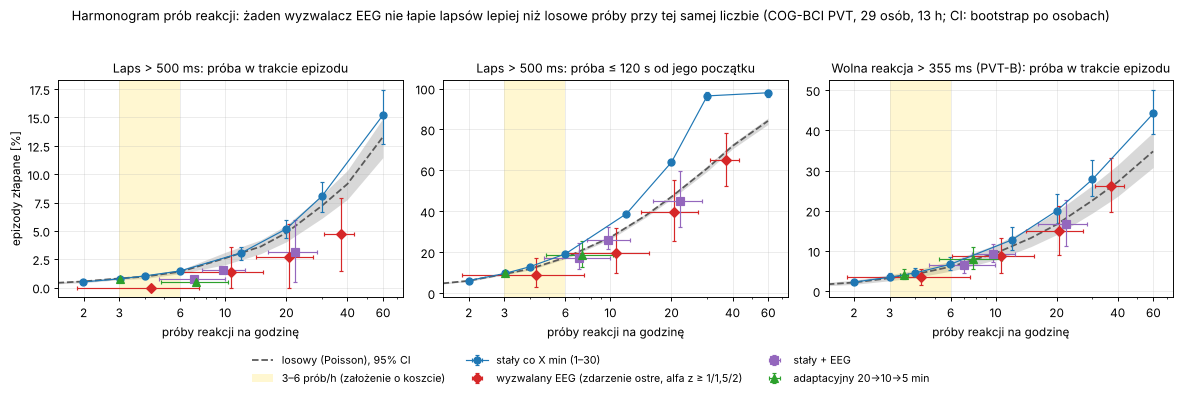

In [13]:
STYLE = {"fixed": ("tab:blue", "o"), "eeg": ("tab:red", "D"), "combo": ("tab:purple", "s"), "adapt": ("tab:green", "^")}
LABEL = {"fixed": "stały co X min (1–30)", "eeg": "wyzwalany EEG (zdarzenie ostre, alfa z ≥ 1/1,5/2)",
         "combo": "stały + EEG", "adapt": "adaptacyjny 20→10→5 min"}


def panel(ax, R, N, col, title):
    x = N.probes_h.map(lambda v: v[0]).values
    y, lo, hi = (np.array([100 * v[i] for v in N[col]]) for i in range(3))
    ax.fill_between(x, lo, hi, color="0.75", alpha=0.6, lw=0)
    ax.plot(x, y, color="0.35", lw=1.5, ls="--", label="losowy (Poisson), 95% CI")
    ax.axvspan(3, 6, color="gold", alpha=0.18, lw=0, label="3–6 prób/h (założenie o koszcie)")
    for kind, (c, m) in STYLE.items():
        g = R[R.kind == kind]
        px = np.array([v[0] for v in g.probes_h]); py = np.array([100 * v[0] for v in g[col]])
        ex = np.array([[v[0] - v[1], v[2] - v[0]] for v in g.probes_h]).T
        ey = np.array([[100 * (v[0] - v[1]), 100 * (v[2] - v[0])] for v in g[col]]).T
        ax.errorbar(px, py, xerr=ex, yerr=ey, fmt=m, color=c, ms=6, capsize=2, lw=1,
                    ls="-" if kind == "fixed" else "none", label=LABEL[kind])
    ax.set_xscale("log"); ax.set_xticks([1, 2, 3, 6, 10, 20, 40, 60]); ax.set_xticklabels([1, 2, 3, 6, 10, 20, 40, 60])
    ax.xaxis.set_minor_formatter(plt.NullFormatter()); ax.set_xlim(1.5, 75); ax.set_xlabel("próby reakcji na godzinę"); ax.set_title(title, fontsize=10.5)


fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
panel(axes[0], OUT[LAPSE_MS][1], OUT[LAPSE_MS][2], "caught", "Laps > 500 ms: próba w trakcie epizodu")
panel(axes[1], OUT[LAPSE_MS][1], OUT[LAPSE_MS][2], "w120", "Laps > 500 ms: próba ≤ 120 s od jego początku")
panel(axes[2], OUT[LAPSE_B_MS][1], OUT[LAPSE_B_MS][2], "caught", "Wolna reakcja > 355 ms (PVT-B): próba w trakcie epizodu")
axes[0].set_ylabel("epizody złapane [%]")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=3, fontsize=9, frameon=False)
fig.suptitle("Harmonogram prób reakcji: żaden wyzwalacz EEG nie łapie lapsów lepiej niż losowe próby przy tej samej liczbie "
             f"(COG-BCI PVT, {RECS.subject.nunique()} osób, {hours:.0f} h; CI: bootstrap po osobach)", fontsize=11)
plt.tight_layout(rect=(0, 0.1, 1, 0.95))
IMG = Path("../../docs/img")
if IMG.exists():                                    # repo checkout; on Colab the figure is only shown
    fig.savefig(IMG / "probe-schedule-simulation-cogbci.png", dpi=80)
plt.show()

## 7. Ile kosztuje jedna próba i czy drabina 20 → 10 → 5 min się „rozkręca”

Próba produktu to **jedna** reakcja. Ile pojedynczych prób u wypoczętej osoby wypada „niezaliczonych” przy różnych progach?
Drabiny adaptacyjnej nie da się sprawdzić na 27 minutach na osobę, więc dodatkowo liczymy jej zachowanie w długim przebiegu
na danych syntetycznych (niezależne wyniki prób z tym samym odsetkiem wolnych reakcji). To **ekstrapolacja**, nie wynik z danych.

In [14]:
rows = []
for (sub, ses), tr in TRIALS.items():
    info = RECS[(RECS.subject == sub) & (RECS.session == ses)].iloc[0]
    cal, post_ = tr[tr.t < info.cal_end], tr[tr.t >= info.cal_end]
    med = cal.rt_ms.median()                        # personal norm from the calibration minute (~9 trials)
    rows.append(dict(subject=sub, p355=(post_.rt_ms > 355).mean(), p500=(post_.rt_ms > 500).mean(),
                     p15=(post_.rt_ms > 1.5 * med).mean(), med=med))
SP = pd.DataFrame(rows).groupby("subject").mean()
print("Odsetek pojedynczych prób uznanych za 'niezaliczone' u wypoczętych osób (na osobę: mediana [IQR]):")
for c, name in [("p355", "RT > 355 ms (obecny probe_lapse_ms)"), ("p500", "RT > 500 ms"),
                ("p15", "RT > 1,5 × mediana z minuty kalibracji")]:
    print(f"  {name:42s} {100 * SP[c].median():5.1f}%  [{100 * SP[c].quantile(.25):.1f}–{100 * SP[c].quantile(.75):.1f}%]")
print(f"mediana RT z minuty kalibracji: {SP.med.median():.0f} ms (osoby: {SP.med.min():.0f}–{SP.med.max():.0f})")


def long_run(p_slow, event_rate_h, use_events, hours_=500, seed=0):
    """Extrapolation, not data: the ladder on a synthetic stream (trial every 6.7 s, each slow with p_slow,
    acute events as a Poisson process)."""
    rng = np.random.default_rng(seed)
    T = hours_ * 3600
    tv = np.arange(0, T, 6.7)
    P = dict(trials_v=tv, rt=np.zeros(len(tv)), slow=rng.random(len(tv)) < p_slow, T=T,
             acute=np.sort(rng.uniform(0, T, rng.poisson(event_rate_h * hours_))))
    pr = adaptive(use_events)(P, rng)
    return len(pr) / hours_


EVENT_RATE = n_acute / hours
print(f"\nDrabina 20→10→5 min w długim przebiegu (ekstrapolacja: niezależne wyniki prób, zdarzenia ostre {EVENT_RATE:.1f}/h jak w PVT):")
for c, name in [("p500", "> 500 ms"), ("p15", "> 1,5 × mediana"), ("p355", "> 355 ms")]:
    p = SP[c].median()
    print(f"  próba 'niezaliczona' gdy {name:18s} (p = {100 * p:4.1f}%): {long_run(p, 0, False):4.1f} prób/h bez zdarzeń; "
          f"{long_run(p, EVENT_RATE, True):4.1f} prób/h ze zdarzeniami ostrymi; "
          f"{long_run(p, 1.0, True):4.1f} prób/h przy 1 zdarzeniu/h")

Odsetek pojedynczych prób uznanych za 'niezaliczone' u wypoczętych osób (na osobę: mediana [IQR]):
  RT > 355 ms (obecny probe_lapse_ms)         21.6%  [16.5–39.3%]
  RT > 500 ms                                  1.7%  [0.8–2.9%]
  RT > 1,5 × mediana z minuty kalibracji       3.2%  [1.3–5.3%]
mediana RT z minuty kalibracji: 307 ms (osoby: 253–346)

Drabina 20→10→5 min w długim przebiegu (ekstrapolacja: niezależne wyniki prób, zdarzenia ostre 5.7/h jak w PVT):
  próba 'niezaliczona' gdy > 500 ms           (p =  1.7%):  3.0 prób/h bez zdarzeń; 10.6 prób/h ze zdarzeniami ostrymi;  4.4 prób/h przy 1 zdarzeniu/h
  próba 'niezaliczona' gdy > 1,5 × mediana    (p =  3.2%):  3.1 prób/h bez zdarzeń; 10.7 prób/h ze zdarzeniami ostrymi;  4.4 prób/h przy 1 zdarzeniu/h
  próba 'niezaliczona' gdy > 355 ms           (p = 21.6%):  4.3 prób/h bez zdarzeń; 11.8 prób/h ze zdarzeniami ostrymi;  6.2 prób/h przy 1 zdarzeniu/h


Zdarzenia ostre u wypoczętych osób: jak często wywołałyby próbę przy różnych przerwach i jak często zdarzają się dwa w jednym nagraniu (reguła STOP z §5.2).

In [15]:
# Acute events in rested, eyes-open PVT: how often would they trigger probes or the two-event STOP rule?
ev_merged = {k: space_out(v[1.5][0], 20.0) for k, v in ACUTE_PROBES.items()}   # events < 20 s apart = one (§5.2)
n_ev = sum(len(v) for v in ev_merged.values())
print(f"zdarzenia ostre po scaleniu < 20 s: {n_ev} ({n_ev / hours:.1f}/h); nagrania z >= 2 zdarzeniami: "
      f"{sum(len(v) >= 2 for v in ev_merged.values())} z {len(ev_merged)}; osoby z jakimkolwiek zdarzeniem: "
      f"{len({k[0] for k, v in ev_merged.items() if len(v)})} z {RECS.subject.nunique()}")
for cd in (45, 120, 300, 600):
    n = sum(len(space_out(v[1.5][0] + EVENT_DELAY_S, cd)) for v in ACUTE_PROBES.values())
    print(f"  próby po zdarzeniu przy przerwie {cd:3d} s: {n / hours:.1f}/h")

zdarzenia ostre po scaleniu < 20 s: 69 (5.3/h); nagrania z >= 2 zdarzeniami: 13 z 87; osoby z jakimkolwiek zdarzeniem: 12 z 29
  próby po zdarzeniu przy przerwie  45 s: 4.3/h
  próby po zdarzeniu przy przerwie 120 s: 3.2/h
  próby po zdarzeniu przy przerwie 300 s: 2.3/h
  próby po zdarzeniu przy przerwie 600 s: 1.7/h


### Wrażliwość na regułę scalania epizodów (30 s wobec 60 s)

In [16]:
SENS = ["stały co 10 min", "stały co 20 min", "po zdarzeniu ostrym", "podprogowa alfa z ≥ 1,5 (obecny produkt)"]
rows = []
for thr in (LAPSE_MS, LAPSE_B_MS):
    for merge in (30.0, 60.0):
        PPm = [person_timeline(s, thr, merge) for s in RECS.subject.unique()]
        n_ep = sum(len(p["first"]) for p in PPm)
        for i, name in enumerate(SENS):
            fn, kind = SCHEDULES[name]
            rp = kind != "eeg"
            D, N = simulate(PPm, fn, 50 if rp else 1, 1 if rp else 50, seed=i)
            r = boot(D, N, 500)
            rows.append({"próg [ms]": thr, "scalanie [s]": merge, "epizody": n_ep, "harmonogram": name,
                         "złapane [%]": fmt(r["caught"]), "losowo [%]": fmt(r["null_caught"]), "różnica [pp]": fmt(r["diff_caught"])})
print(pd.DataFrame(rows).to_string(index=False))

 próg [ms]  scalanie [s]  epizody                              harmonogram      złapane [%]       losowo [%]     różnica [pp]
       500          30.0      147                          stały co 10 min    1.8 [1.4–2.1]    1.5 [1.2–1.8]   0.3 [-0.0–0.6]
       500          30.0      147                          stały co 20 min    0.9 [0.7–1.1]    1.1 [0.8–1.3]  -0.1 [-0.4–0.2]
       500          30.0      147                      po zdarzeniu ostrym    0.0 [0.0–0.0]    0.6 [0.2–1.2] -0.6 [-1.2–-0.2]
       500          30.0      147 podprogowa alfa z ≥ 1,5 (obecny produkt)    2.7 [0.0–5.4]    4.3 [2.2–7.1]  -1.6 [-3.3–0.1]
       500          60.0      122                          stały co 10 min    3.1 [2.3–4.0]    3.0 [2.2–3.8]   0.1 [-0.5–0.6]
       500          60.0      122                          stały co 20 min    1.9 [1.3–2.5]    2.0 [1.4–2.5]  -0.1 [-0.6–0.4]
       500          60.0      122                      po zdarzeniu ostrym    0.0 [0.0–0.0]    1.2 [0.3–2.4] -1.2 [-2.

## 8. Wnioski

**W skrócie: przy tej częstości lapsów harmonogramy są nie do odróżnienia od losowych prób. Każdy z nich, także wyzwalany przez EEG,
łapie tyle lapsów, ile wynika z samej liczby prób.** Przy 3 próbach na godzinę (stały co 20 min) próba trafia w trwający laps > 500 ms
w **0,8%** epizodów (losowo 0,7%) i w ciągu 120 s od jego początku w **9,6%** (losowo 9,6%). Wyzwalacze EEG nie dodają nic ponad
liczbę prób: podprogowa alfa z ≥ 1,5 (obecny produkt) robi **20,5 prób/h** i łapie 2,7% epizodów, a losowe próby w tej samej
liczbie 4,2% (różnica −1,5 pp [−3,2; 0,1]). Próby po zdarzeniu ostrym nie złapały **żadnego** z 147 epizodów i żadna z ich
odpowiedzi nie była wolniejsza niż 500 ms. Częstość prób trzeba więc ustawić według **kosztu dla użytkownika**,
nie według skuteczności. Te dane nie pozwalają wybrać odstępu na podstawie skuteczności.

**Szczegóły (wszystkie liczby z komórek wyżej):**

1. **Dane i rzadkość lapsów.** 29 osób, 87 nagrań, 13,1 h po kalibracji (ok. 27 min na osobę). RT > 500 ms ma **2,5%** prób
   (174 z 6839). Daje to 147 epizodów (11,3/h), w 86% z jedną wolną reakcją, z oknem o medianie 6 s. Epizody zajmują **2,9%** czasu,
   a 4 z 29 osób nie mają żadnego. RT > 355 ms ma **25,8%** prób, a 461 epizodów zajmuje **39,3%** czasu.
   Przy progu 355 ms „laps” to zwykły stan wypoczętej osoby, a nie rzadkie zdarzenie.
2. **Wartość próby zależy od częstości lapsów, nie od harmonogramu.** Harmonogram ślepy na stan człowieka łapie ok.
   (długość okna epizodu) / (odstęp). Trafność próby (odsetek prób z wolną odpowiedzią) wynosi **2,1–2,3%** przy 500 ms
   i **23–24%** przy 355 ms dla każdego stałego odstępu, czyli tyle, ile wynosi odsetek wolnych reakcji. Przy 500 ms ok. 97% prób
   trafia poza epizod (np. co 20 min: 2,9 z 3,0 prób/h). Regularny odstęp jest minimalnie lepszy od losowego tylko przy bardzo
   gęstych próbach (co 1 min: 15,2% wobec 13,4%), co przy kosztach prób nie ma znaczenia praktycznego.
3. **Wyzwalacze EEG (500 ms, definicja główna).** Po zdarzeniu ostrym: 4,3 prób/h, 0,0% złapanych (losowo 0,8%; −0,8 pp [−1,3; −0,3]).
   Podprogowa alfa: z ≥ 1,0: 37,1/h, 4,8% wobec 7,9% losowo; z ≥ 1,5: 20,5/h, 2,7% wobec 4,2%; z ≥ 2,0: 10,6/h, 1,4% wobec 2,2%.
   Dołożenie wyzwalaczy EEG do harmonogramu stałego zwiększa liczbę prób, ale nie trafność: stały 20 min + po zdarzeniu daje 7,0/h
   i 0,8% złapanych (losowo 1,3%), a stały 20 min + alfa z ≥ 1,5 daje 22,1/h i 3,2% (losowo 4,5%).
   **Jedyny ślad sygnału:** w definicji pomocniczej (próba ≤ 120 s po początku epizodu) podprogowa alfa jest kilka punktów nad losowym
   (z ≥ 1,5: 39,5% wobec 35,7%, +3,8 pp [−0,6; 9,3]; stały 20 min + alfa: +4,2 pp [0,3; 9,3]). Tylko jeden z tych przedziałów
   nie obejmuje zera, a testowaliśmy kilkanaście harmonogramów i dwie definicje. Uznajemy to za szum. Nie jest to podstawa
   do wyzwalania prób.
4. **Próg 355 ms.** Wszystkie harmonogramy leżą na krzywej losowej (np. podprogowa alfa z ≥ 1,5: 15,0% wobec 14,2%;
   po zdarzeniu: 3,5% wobec 3,5%; stały co 10 min: 6,7% wobec 6,2%).
5. **Koszt pojedynczej próby.** U wypoczętych osób jedna reakcja jest „niezaliczona” przy progu 355 ms w **21,6%** przypadków
   (mediana na osobę, IQR 16,5–39,3%), przy 500 ms w 1,7%, a przy 1,5 × medianie z minuty kalibracji w 3,2% (IQR 1,3–5,3%).
   Obecny `probe_lapse_ms = 355` zastosowany do jednej reakcji oznacza, że co czwarta–piąta próba wypoczętej osoby odejmuje
   `lapse_penalty` od rezerwy i (w drabinie) skraca odstęp.
6. **Drabina 20 → 10 → 5 min** (parametry to założenia). Na 27 minutach na osobę nie da się jej sprawdzić. Przy 500 ms prawie
   żadna próba nie wychodzi wolna, więc drabina zostaje na 20 min (3,0 prób/h, 0,7% złapanych, tyle co losowo). Ekstrapolacja
   (niezależne wyniki prób): bez zdarzeń ostrych drabina daje 3,0 prób/h przy progu 500 ms, 3,1 przy 1,5 × mediana i 4,3 przy 355 ms.
   Jeśli zdarzenia ostre też skracają odstęp, przy częstości zdarzeń z tych danych (5,7/h) rośnie to do **ok. 11 prób/h**
   (10,6–11,8), czyli powyżej założonego budżetu. Przy 1 zdarzeniu/h: 4,4–6,2 prób/h.
7. **Zdarzenia ostre u wypoczętych osób z otwartymi oczami.** Detektor (z > 2,5 przez ≥ 3 s) zadziałał 74 razy (5,7/h). Po scaleniu
   zdarzeń < 20 s zostaje 69 (5,3/h), u 12 z 29 osób, a 13 z 87 nagrań ma ≥ 2 zdarzenia w ok. 9 minut. Przerwa między próbami
   po zdarzeniu: 45 s daje 4,3 prób/h, 120 s 3,2/h, 300 s 2,3/h, 600 s 1,7/h.
8. **Wrażliwość.** Scalanie epizodów co 60 s zamiast 30 s (500 ms: 122 epizody zamiast 147) nie zmienia obrazu: stały co 10 min
   3,1% wobec 3,0% losowo, po zdarzeniu 0,0% wobec 1,2%, alfa z ≥ 1,5 5,7% wobec 7,1%.

### Parametry do config.py (issue #14, #15)

Wszystkie wartości to **założenia tymczasowe**. Dane pokazują tylko, że skuteczność nie rozróżnia odstępów, więc decyduje koszt.
Założenie projektowe (nie wynik z danych): użytkownik toleruje **3–6 prób na godzinę**.

| Parametr (proponowana nazwa) | Teraz | Propozycja | Podstawa |
|---|---|---|---|
| wyzwalanie podprogową alfą (`probe_z`, `probe_min_s`) | 1,5 / 2 s | **wyłączyć** (usunąć albo `probe_z = None`) | 20,5 prób/h przy trafności ≤ losowej (pkt 3); sesja Wojtka: ok. 44/h; zgodne z issue #14 |
| `probe_interval_s` (odstęp bazowy, poziom niski) | brak | **1200** (20 min, 3 próby/h) | koszt; 15–30 min dają tę samą trafność na próbę (pkt 2) |
| `probe_interval_mid_s` (poziom średni) | brak | **600** (10 min, 6 prób/h) | górna granica założonego budżetu; nie sprawdzone na danych (pkt 6) |
| `probe_interval_high_s` (poziom wysoki) | brak | **300** (5 min, 12 prób/h), tylko jako stan przejściowy | założenie z §5.3; nie sprawdzone na danych |
| `probe_recover_n` (dobre próby do powrotu o poziom) | brak | **2** | założenie |
| co podnosi poziom drabiny | – | **niezaliczona próba** albo kontekst (A9). Zdarzenie ostre samo nie skraca odstępu, tylko wywołuje jedną próbę | ze zdarzeniami drabina rośnie do ok. 11 prób/h (pkt 6), a próby po zdarzeniach nie trafiły ani jednego wolnego RT (pkt 3) |
| `probe_event_delay_s` (próba po zdarzeniu ostrym) | brak | **5** s po zakończeniu zdarzenia | issue #14; krótko, żeby próba była potwierdzeniem zamknięcia oczu |
| `probe_cooldown_s` (min. odstęp między dowolnymi próbami) | 45 | **300** | 2,3 prób/h z samych zdarzeń zamiast 4,3/h (pkt 7); razem z bazą 20 min mieści się w budżecie 3–6/h |
| `probe_lapse_ms` (próba niezaliczona) | 355 | **max(500, 1,5 × mediana RT z kalibracji)**; w razie braku kalibracji 500 | przy 355 ms 21,6% pojedynczych prób wypoczętych osób jest „niezaliczonych” (pkt 5); próg 1,5 × mediana: 3,2% |
| brak odpowiedzi (`probe_timeout_ms`) | 3000 | bez zmian, liczyć jako niezaliczoną | w tych danych nie było braków odpowiedzi, więc dane nic tu nie mówią |

**Czego te dane nie rozstrzygają:**
- czy jakikolwiek wyzwalacz (EEG, kontekst, wynik próby) łapie lapsy lepiej niż losowo, **gdy lapsów jest dużo** (noc, deprywacja snu,
  długa monotonia). U wypoczętych osób w 10-minutowym PVT lapsy są pojedyncze i rzadkie (2,5% prób), więc żaden harmonogram nie ma czego łapać;
- czy drabina 20 → 10 → 5 min pomaga: 27 minut na osobę to za mało, a wolnych prób przy 500 ms prawie nie ma. Wartości drabiny to założenia;
- który odstęp bazowy (15, 20 czy 30 min) jest lepszy: na krzywej skuteczności wszystkie leżą na krzywej losowej;
- jak często zdarzenia ostre wystąpią na suchych elektrodach BrainAccess MINI i u sennych osób. Tutaj to żelowe EEG z 63 kanałów
  przeliczone do 8 kanałów z referencją Fp1.

**Ograniczenia:**
- Próbę produktu udajemy pierwszą próbą PVT w ciągu 15 s. Prawdziwa próba przerywa pracę, więc sama może zmieniać czujność.
- Sesje jednej osoby (odstęp tygodnia) sklejamy w jedną oś czasu. Harmonogramy EEG liczymy osobno w każdej sesji.
- Okno epizodu ±3 s i scalanie 30 s to nasze definicje. Wariant 60 s (sekcja 7) nie zmienia wniosków.
- Filtr 1–40 Hz jest tu offline (zerowa faza), a produkt filtruje przyczynowo. Kalibracja to pierwsza minuta zadania, jak w produkcie.
- Przedziały ufności pochodzą z bootstrapu po 29 osobach (25 z epizodem > 500 ms). Przy wielu porównaniach pojedynczy przedział
  bez zera (pkt 3) nie jest dowodem.

**Zgodność z dokumentacją zespołu:**
- `docs/analiza-i-adaptacja.md` §5.2 („próba tylko po zdarzeniu ostrym albo z harmonogramu, nigdy z podprogowego wzrostu alfy”)
  i issue #14 (usunąć `probe_z`) **zgadzają się** z wynikiem.
- **Rozbieżność 1:** issue #14 pkt 2 i komentarz w `config.py` oceniają próbę progiem PVT-B 355 ms. Ten próg dotyczy liczenia lapsów
  w 3-minutowym teście z wieloma bodźcami. Dla **jednej** reakcji daje 21,6% „niezaliczeń” u wypoczętych osób. Issue #14 pkt 3
  i §5.2 (osobista norma 1,5 × mediana) są tu lepsze i ten wariant proponujemy.
- **Rozbieżność 2:** §5.2 każe przejść w STOP po „dwóch odrębnych zdarzeniach ostrych”, a §5.3 i issue #15 skracać odstęp po zdarzeniu.
  U wypoczętych osób z otwartymi oczami detektor zadziałał ≥ 2 razy w 13 z 87 dziesięciominutowych nagrań. Próby po tych zdarzeniach
  nie trafiły żadnej wolnej reakcji. Zdarzenie ostre powinno więc wywoływać próbę jako potwierdzenie, a decyzję (UWAGA, STOP,
  krótszy odstęp) powinien podejmować dopiero jej wynik.